In [5]:
import os
import json

import pandas as pd
import numpy as np
from scipy.stats import entropy
import random
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import build_df, standardize_df
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    YEARS,
    NUM_CLUSTERS,
)

# 1. Build dataframes

In [11]:
# build df
DF_DAILY_FNAME = os.path.join(BASE_OUTPUT, "dataframes/df_daily.csv")
OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

if not os.path.exists(DF_DAILY_FNAME):
    print("Calculating df_daily...")
    df_daily, _ = build_df()
    df_daily = df_daily.reset_index()
    df_daily["year"] = df_daily["Date"].dt.year
    df_daily.to_csv(DF_DAILY_FNAME)
else:
    print("Taking df_daily from memory...")
    df_daily = pd.read_csv(DF_DAILY_FNAME, index_col=0)

df_std = standardize_df(df_daily, ["NL_OFF", "NL_ON", "NL_SOLAR", "NL_TEMP"])
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
# compute some residual load, but not any weighting. Just to see joint-tail behavior
df_daily["Residual_ish"] = df_std["NL_TEMP"] + (df_std["NL_SOLAR"] + df_std["NL_OFF"] + df_std["NL_ON"])

Taking df_daily from memory...


In [9]:
selection = json.load(open(os.path.join(OUTPUT_DIR, "selected_sa_cost_2.0_0.98_5000_0.json")))
selected = selection["selected"]

In [14]:
# random draw of NUM_CLUSTER years for comparison
random_models = random.choices(MODELS, k=NUM_CLUSTERS)
random_years = random.choices(YEARS, k=NUM_CLUSTERS)

# build df with daily data of selected years
frames_centroids = []
frames_random = []
for i, (model, year) in enumerate(selected):
    # model_centroid, year_centroid = row["model"], row["Date"]
    model_random, year_random = random_models[i], random_years[i]
    df_centroid = df_daily.query(f"model == '{model}' and year == {year}")
    df_random = df_daily.query(f"model == '{model_random}' and year == {year_random}")
    frames_centroids.append(df_centroid)
    frames_random.append(df_random)

df_centroids = pd.concat(frames_centroids, ignore_index=True)
df_random = pd.concat(frames_random, ignore_index=True)

# 2. Perform comparison

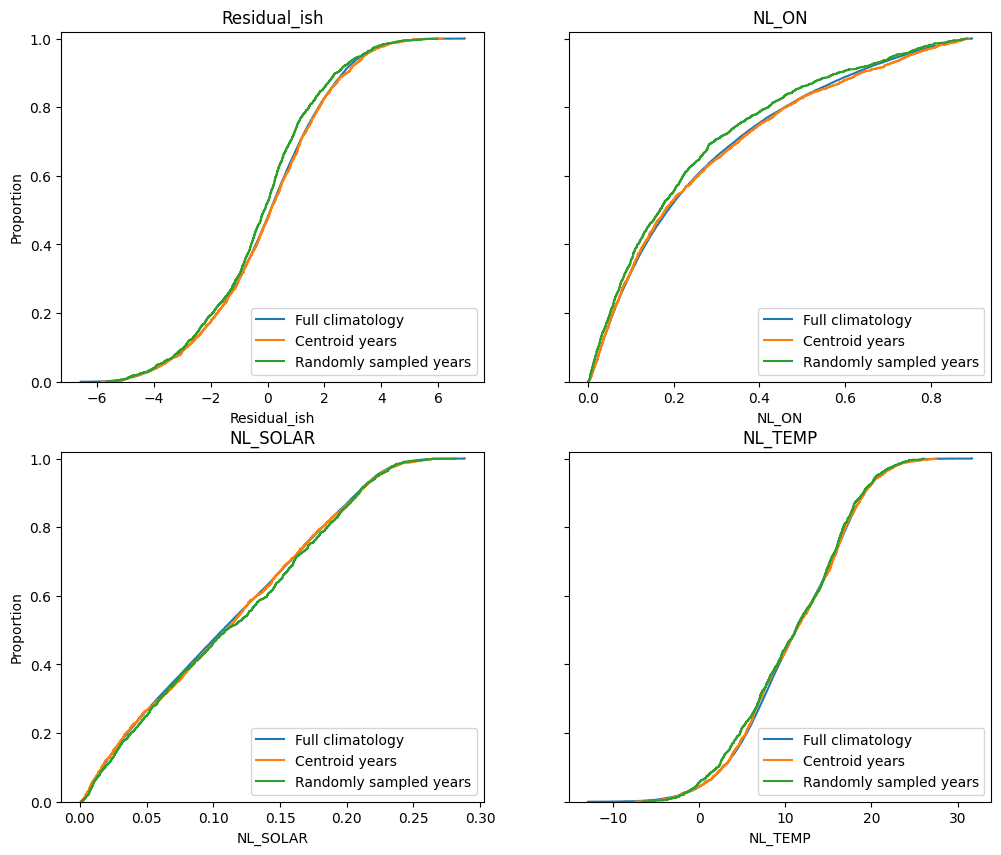

In [ ]:
# just simple ECDF plots for visual inspection
columns = ["Residual_ish", "NL_ON", "NL_SOLAR", "NL_TEMP"]

fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

for i, col in enumerate(columns):
    ax = axs.flat[i]
    sns.ecdfplot(df_daily, x=col, label="Full climatology", ax=ax)
    sns.ecdfplot(df_centroids, x=col, label="Centroid years", ax=ax)
    sns.ecdfplot(df_random, x=col, label="Randomly sampled years", ax=ax)
    ax.set_title(col)
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")

# Hide any unused axes (in case columns < 4)
for j in range(len(columns), 4):
    axs.flat[j].axis("off")

,variable,subset,MAE,RMSE,MaxAbs
0,Residual_ish,Centroid,0.055328,0.120085,0.765742
1,Residual_ish,Random,0.160430,0.205878,0.969504
2,NL_ON,Centroid,0.003006,0.005549,0.028582
3,NL_ON,Random,0.012812,0.018975,0.051758
4,NL_SOLAR,Centroid,0.000951,0.002025,0.023008
5,NL_SOLAR,Random,0.001902,0.002574,0.007901
6,NL_TEMP,Centroid,0.300210,0.663335,5.522064
7,NL_TEMP,Random,0.522281,0.879681,6.391275


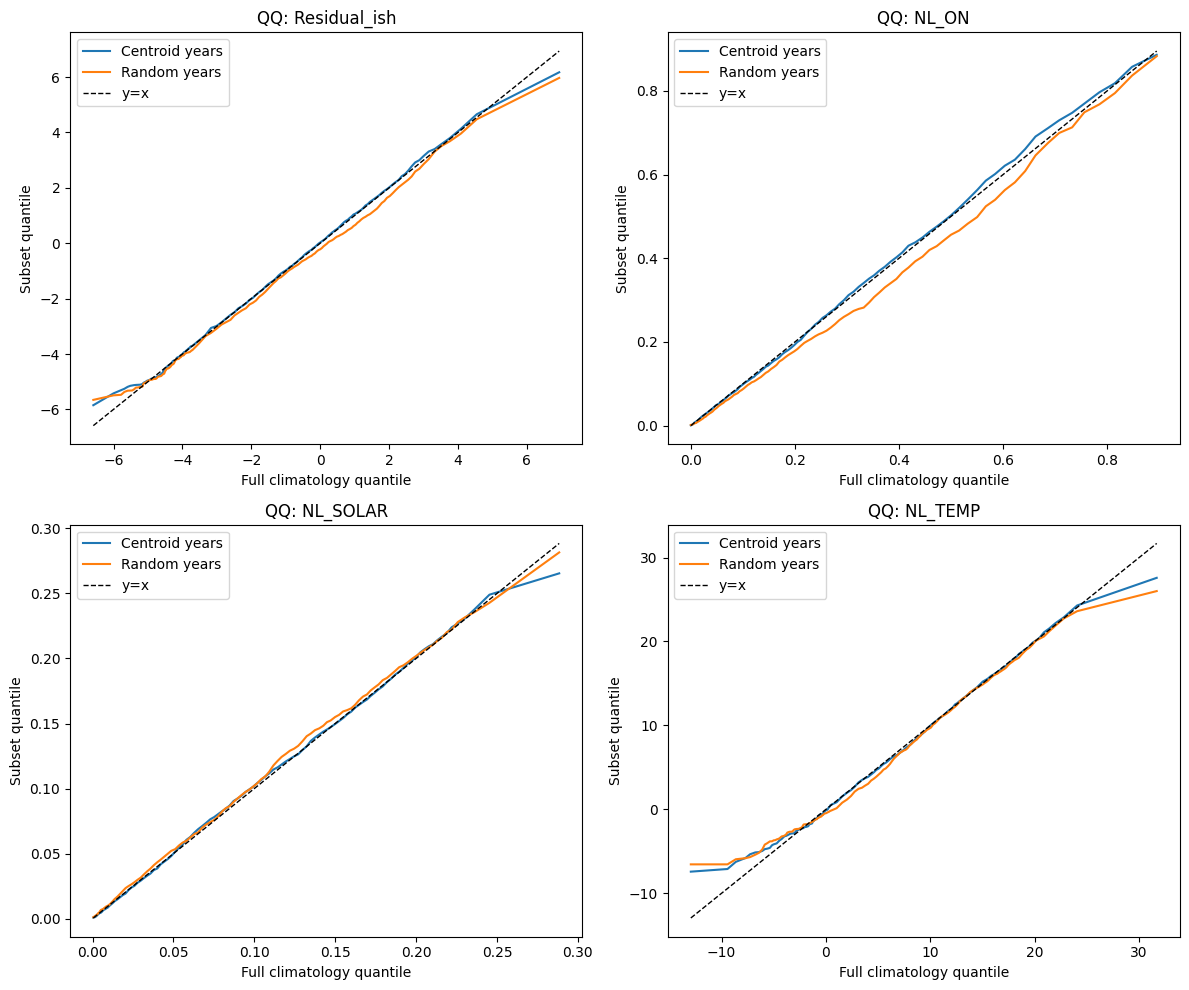

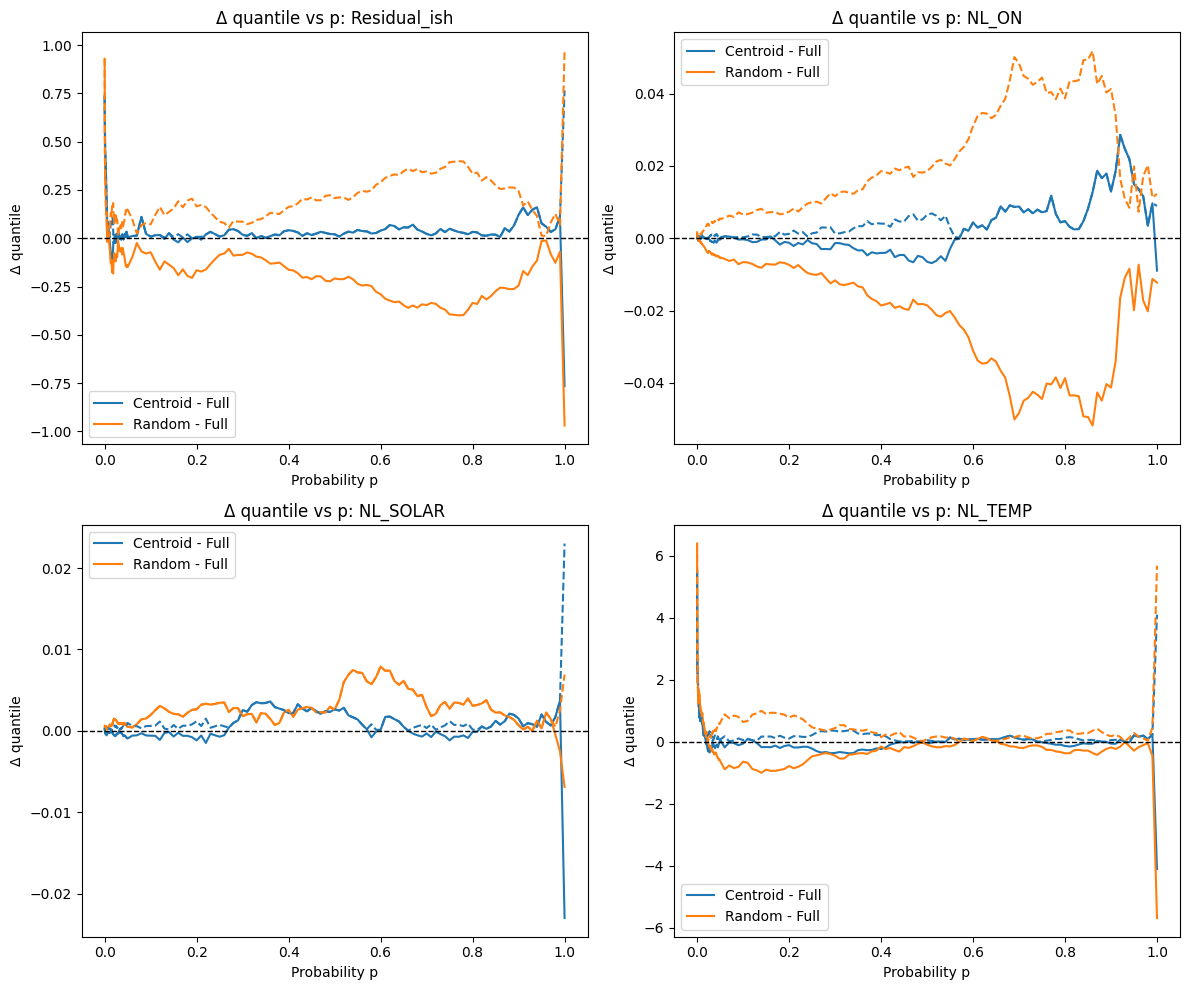

In [18]:
# Quantile comparison: invert ECDFs and compare
dense = np.linspace(0.0, 0.05, 100, endpoint=False)
coarse = np.linspace(0.05, 1.0, 96)
probs = np.concatenate([dense, coarse])

# Container for metrics rows
metrics_rows = []

# Prepare figures: QQ plots and quantile differences
fig_qq, axs_qq = plt.subplots(2, 2, figsize=(12, 10))
fig_diff, axs_diff = plt.subplots(2, 2, figsize=(12, 10), sharey=False)

for i, col in enumerate(columns):
    # Compute quantiles at common probabilities
    q_full = df_daily[col].quantile(probs)
    q_cent = df_centroids[col].quantile(probs)
    q_rand = df_random[col].quantile(probs)

    # Metrics vs full
    diff_cent = (q_cent - q_full).values
    diff_rand = (q_rand - q_full).values
    mae_cent = np.mean(np.abs(diff_cent))
    rmse_cent = np.sqrt(np.mean(diff_cent**2))
    maxabs_cent = np.max(np.abs(diff_cent))
    mae_rand = np.mean(np.abs(diff_rand))
    rmse_rand = np.sqrt(np.mean(diff_rand**2))
    maxabs_rand = np.max(np.abs(diff_rand))

    metrics_rows.append({
        "variable": col,
        "subset": "Centroid",
        "MAE": mae_cent,
        "RMSE": rmse_cent,
        "MaxAbs": maxabs_cent,
    })
    metrics_rows.append({
        "variable": col,
        "subset": "Random",
        "MAE": mae_rand,
        "RMSE": rmse_rand,
        "MaxAbs": maxabs_rand,
    })

    # QQ plot: y(subset) vs x(full)
    axq = axs_qq.flat[i]
    x = q_full.values
    axq.plot(x, q_cent.values, label="Centroid years")
    axq.plot(x, q_rand.values, label="Random years")
    # 45-degree line
    lo, hi = np.nanmin(x), np.nanmax(x)
    axq.plot([lo, hi], [lo, hi], "k--", lw=1, label="y=x")
    axq.set_title(f"QQ: {col}")
    axq.set_xlabel("Full climatology quantile")
    axq.set_ylabel("Subset quantile")
    axq.legend(loc="best")

    # Quantile differences vs probability
    axd = axs_diff.flat[i]
    axd.plot(probs, diff_cent, c= 'C0', label="Centroid - Full")
    axd.plot(probs, diff_rand, c= 'C1', label="Random - Full")
    axd.plot(probs, np.abs(diff_cent), c= 'C0', ls='--')
    axd.plot(probs, np.abs(diff_rand), c= 'C1', ls='--')
    axd.axhline(0.0, color="k", lw=1, ls="--")
    axd.set_title(f"Δ quantile vs p: {col}")
    axd.set_xlabel("Probability p")
    axd.set_ylabel("Δ quantile")
    axd.legend(loc="best")

# Hide any unused axes (in case fewer than 4 columns)
for j in range(len(columns), 4):
    axs_qq.flat[j].axis("off")
    axs_diff.flat[j].axis("off")

fig_qq.tight_layout()
fig_diff.tight_layout()

metrics_df = pd.DataFrame(metrics_rows)
metrics_df


# 3. Look at longer-events (non-optimized)